In [24]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix
)

In [25]:
df = pd.read_csv("../data/processed/cleaned_emotions.csv")

print(df.shape)
print(df.head())

(15939, 5)
                                                text  emotion  word_count  \
0                            i didnt feel humiliated  sadness           4   
1  i can go from feeling so hopeless to so damned...  sadness          21   
2   im grabbing a minute to post i feel greedy wrong    anger          10   
3  i am ever feeling nostalgic about the fireplac...     love          18   
4                               i am feeling grouchy    anger           4   

                                       text_original  \
0                            i didnt feel humiliated   
1  i can go from feeling so hopeless to so damned...   
2   im grabbing a minute to post i feel greedy wrong   
3  i am ever feeling nostalgic about the fireplac...   
4                               i am feeling grouchy   

                                          text_clean  
0                            i didnt feel humiliated  
1  i can go from feeling so hopeless to so damned...  
2   im grabbing a minute

In [26]:
X = df["text_clean"]
y = df["emotion"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (15939,)
Target: (15939,)


In [27]:
X = df["text_clean"]
y = df["emotion"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 12751
Testing samples: 3188

Training distribution:
emotion
joy         0.335
sadness     0.292
anger       0.135
fear        0.121
love        0.081
surprise    0.035
Name: proportion, dtype: float64

Testing distribution:
emotion
joy         0.335
sadness     0.293
anger       0.135
fear        0.121
love        0.081
surprise    0.035
Name: proportion, dtype: float64


In [28]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (12751, 10000)
Testing matrix: (3188, 10000)


In [29]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        class_weight="balanced"
    )
}

results = []

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )
    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

    trained_models[name] = model

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print("-" * 40)

Training Logistic Regression...
Accuracy: 0.8642
Macro F1: 0.8377
Weighted F1: 0.8659
----------------------------------------
Training Naive Bayes...
Accuracy: 0.6706
Macro F1: 0.4365
Weighted F1: 0.6085
----------------------------------------
Training Linear SVM...
Accuracy: 0.8899
Macro F1: 0.8590
Weighted F1: 0.8906
----------------------------------------


In [30]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
)

print(results_df.round(4))

                 Model  Accuracy  Macro F1  Weighted F1
2           Linear SVM    0.8899    0.8590       0.8906
0  Logistic Regression    0.8642    0.8377       0.8659
1          Naive Bayes    0.6706    0.4365       0.6085


In [31]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test_tfidf)

print("Best model:", best_model_name)

print(
    classification_report(
        y_test,
        y_pred_best,
        zero_division=0
    )
)

Best model: Linear SVM
              precision    recall  f1-score   support

       anger       0.86      0.90      0.88       430
        fear       0.85      0.86      0.86       385
         joy       0.93      0.90      0.92      1069
        love       0.76      0.85      0.80       258
     sadness       0.93      0.91      0.92       933
    surprise       0.79      0.78      0.78       113

    accuracy                           0.89      3188
   macro avg       0.85      0.87      0.86      3188
weighted avg       0.89      0.89      0.89      3188



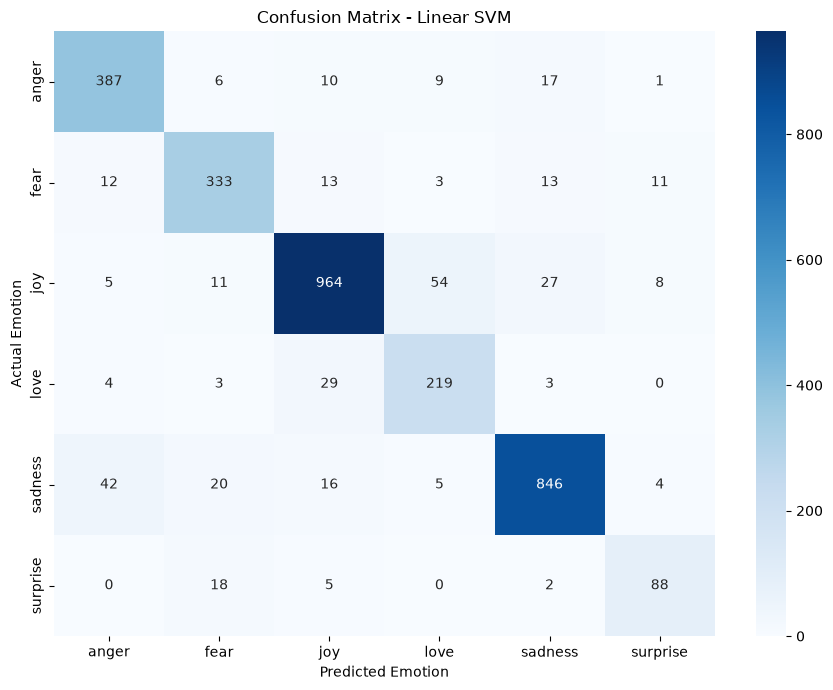

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=best_model.classes_
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()

In [33]:
error_analysis = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred_best
})

misclassified = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
]

print("Total misclassified:", len(misclassified))

misclassified.head(20)

Total misclassified: 351


,text,actual,predicted
1,i feel determined even if nervous about the un...,joy,fear
12,i have good camwhore skill thanks to instagram...,sadness,joy
15,i am feeling generous and seasonal,joy,love
19,i like to pray a decade whenever im feeling st...,anger,fear
40,i feel a little tortured and lost,anger,fear
41,im making more mistakes thinking less clearly ...,fear,joy
42,i feel blessed to be his sister,joy,love
50,i am also posting this because i am trying to ...,joy,love
86,i dont think many people will get how i feel g...,joy,sadness
88,i can feel what hes feeling but not quite beca...,joy,love


In [34]:
misclassified["confusion"] = (
    misclassified["actual"] + " -> " +
    misclassified["predicted"]
)

print(
    misclassified["confusion"]
    .value_counts()
    .head(10)
)

confusion
joy -> love         54
sadness -> anger    42
love -> joy         29
joy -> sadness      27
sadness -> fear     20
surprise -> fear    18
anger -> sadness    17
sadness -> joy      16
fear -> joy         13
fear -> sadness     13
Name: count, dtype: int64


In [35]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LinearSVC(class_weight="balanced"))
])


param_grid = {
    "tfidf__max_features": [10000, 20000],
    "tfidf__min_df": [2, 3],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "classifier__C": [0.1, 0.5, 1, 2]
}


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation Macro F1:")
print(grid_search.best_score_)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best parameters:
{'classifier__C': 0.5, 'tfidf__max_features': 10000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}

Best cross-validation Macro F1:
0.8607936038600121


In [36]:
best_svm = grid_search.best_estimator_

y_pred_tuned = best_svm.predict(X_test)

print("Tuned Linear SVM Results")

print(
    classification_report(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_tuned)
)

print(
    "Macro F1:",
    f1_score(y_test, y_pred_tuned, average="macro")
)

Tuned Linear SVM Results
              precision    recall  f1-score   support

       anger       0.85      0.93      0.89       430
        fear       0.87      0.88      0.87       385
         joy       0.94      0.90      0.92      1069
        love       0.75      0.88      0.81       258
     sadness       0.96      0.91      0.93       933
    surprise       0.75      0.81      0.77       113

    accuracy                           0.90      3188
   macro avg       0.85      0.88      0.87      3188
weighted avg       0.90      0.90      0.90      3188

Accuracy: 0.8980552070263488
Macro F1: 0.8661568987328847


In [37]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation Macro F1:")
print(round(grid_search.best_score_, 4))

Best parameters:
{'classifier__C': 0.5, 'tfidf__max_features': 10000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}

Best cross-validation Macro F1:
0.8608


In [38]:
import joblib
import os
import json

os.makedirs("../models", exist_ok=True)

# Save complete pipeline
joblib.dump(
    best_svm,
    "../models/emotisense_svm.pkl"
)

# Save model metadata
metadata = {
    "model": "Linear SVM",
    "accuracy": accuracy_score(y_test, y_pred_tuned),
    "macro_f1": f1_score(
        y_test,
        y_pred_tuned,
        average="macro"
    ),
    "weighted_f1": f1_score(
        y_test,
        y_pred_tuned,
        average="weighted"
    ),
    "cross_validation_macro_f1": grid_search.best_score_,
    "best_parameters": grid_search.best_params_
}

with open("../models/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model and metadata saved successfully!")

Model and metadata saved successfully!


In [39]:
loaded_model = joblib.load(
    "../models/emotisense_svm.pkl"
)

sample_text = [
    "I am extremely happy today",
    "I feel completely alone and miserable",
    "I am terrified of what might happen"
]

predictions = loaded_model.predict(sample_text)

for text, emotion in zip(sample_text, predictions):
    print(f"Text: {text}")
    print(f"Predicted emotion: {emotion}\n")

Text: I am extremely happy today
Predicted emotion: joy

Text: I feel completely alone and miserable
Predicted emotion: sadness

Text: I am terrified of what might happen
Predicted emotion: fear



In [40]:
test_sentences = [
    "I am grateful",
    "I am grateful for my family",
    "I feel thankful and blessed",
    "I am happy and grateful today",
    "I feel miserable and alone"
]

for sentence in test_sentences:
    prediction = loaded_model.predict([sentence])[0]
    print(f"{sentence} -> {prediction}")

I am grateful -> joy
I am grateful for my family -> joy
I feel thankful and blessed -> joy
I am happy and grateful today -> joy
I feel miserable and alone -> sadness


In [41]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss

calibrated_model = CalibratedClassifierCV(
    estimator=best_svm,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

print("Calibration completed!")

Calibration completed!


In [42]:
y_pred_calibrated = calibrated_model.predict(X_test)

y_prob = calibrated_model.predict_proba(X_test)

print(classification_report(
    y_test,
    y_pred_calibrated,
    zero_division=0
))

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_calibrated)
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        y_pred_calibrated,
        average="macro"
    )
)

print("Log loss:", log_loss(
    y_test,
    y_prob,
    labels=calibrated_model.classes_
))

              precision    recall  f1-score   support

       anger       0.87      0.93      0.90       430
        fear       0.86      0.88      0.87       385
         joy       0.92      0.93      0.93      1069
        love       0.82      0.82      0.82       258
     sadness       0.95      0.92      0.93       933
    surprise       0.82      0.71      0.76       113

    accuracy                           0.90      3188
   macro avg       0.88      0.86      0.87      3188
weighted avg       0.90      0.90      0.90      3188

Accuracy: 0.9043287327478042
Macro F1: 0.8687206912888189
Log loss: 0.28346051430632835


In [43]:
import joblib
import json
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    calibrated_model,
    "../models/emotisense_calibrated.pkl"
)

metadata = {
    "model": "Calibrated Linear SVM",
    "accuracy": 0.9043,
    "macro_f1": 0.8687,
    "weighted_f1": 0.90,
    "log_loss": 0.2835,
    "calibration": "sigmoid"
}

with open("../models/calibrated_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Calibrated model saved!")

Calibrated model saved!
